# Group Assignment 1: Human Activity Detection
In this assignment you will create you own dataset for classification. You will explore which ML algorithms are best to classify this and you will present your best solution. 

- Create your own dataset for custom human motions using Phyphox
- There should be at least 3 distinct types of motions
- The motions should be different to the ones used in the UCI dataset (Not: walking, sitting, standing, laying, stairs)
- Follow the steps and answer the questions given in this notebook

### Generating your dataset:

For this assignment you will create your own dataset of motions that you collect with an Accelerometer and Gyroscope. For this you can use your phone as a sensor.
To be able to collect your data you can best use an app called [phyphox](https://phyphox.org/), this is a free app available in app stores. This app can be configured to acces your sensordata, sample it as given frequency's. you can set it up te have experiment timeslots, and the data with a timestamp can be exported to a needed output format.

![](https://phyphox.org/wp-content/uploads/2019/06/phyphox_dark-1024x274.png)

When you installed the app you can setup a custum experiment by clicking on the + button. Define an experiment name, sample frequency and activate the Accelerometer and Gyroscope. Your custom experiment will be added, you can run it pressing the play button and you will see sensor motion. Pressing the tree dots (...) lets you define timed runs, remote access and exporting data.

Phyphox will generate 2 files with sensor data, one for the Accelerometer and one for the Giro. Both files will have timestamps which might not match the recorded sensor data for each sensor. Please, preprocess and merge the files for using it as your dataset for training, testing and deploying your own supervised learning model.

### steps

With your own generated dataset the similar sequence of steps should be taken to train your model.

These are the generic steps to be taken
1. Frame the problem and look at the big picture.
2. Get the data.
3. Explore the data to gain insights.
4. Prepare the data to better expose the underlying data patterns to Machine Learning algorithms
5. Explore many different models and short-list the best ones.
6. Fine-tune your models and combine them into a great solution.
7. Present your solution.
8. Launch, monitor, and maintain your system.
9. Additional Questions


---
In the Notebook this structure is used for dividing the different steps, so make sure you do the implementation and analisis at these location in the notebook. 

You may add additinal code blocks, but keep the seperation of the given structure.

At the end of each block summarize / comment / conclude your current step in the given textblocks.




By:

Haakon F. Valland

Pedro Mur

Yvette Lopez

# 1. Frame the problem and look at the big picture
Describe the problem at hand and explain your approach

```
# Place your comments / conclusions / insight here
```
The goal of this assignment is to train a ML model that is able to detect a series of human actions (walking, stairs, sitting) using accelerometer and gyroscope data from Phyphox. For it we have recorded our own data with the Phyphox app. The recorded samples of the chosen actions were recorded and exported in .csv format and loaded into python for further data processing.

# 2. Get the data.

Initialize the system, get all needed libraries, retreive the data and import it

> Create your own dataset

> Explain and show (with a few images) which motions you are classifing, how you generated them, what the problems where you encountered in this process! 

The actions chosen to be classified are: Chair spin, jumping and doing squats.

This actions were chosen because they were:
- Not part of the original human activity dataset
- Easy to replicate
- Distinct enough between eachother to make them distinguishable

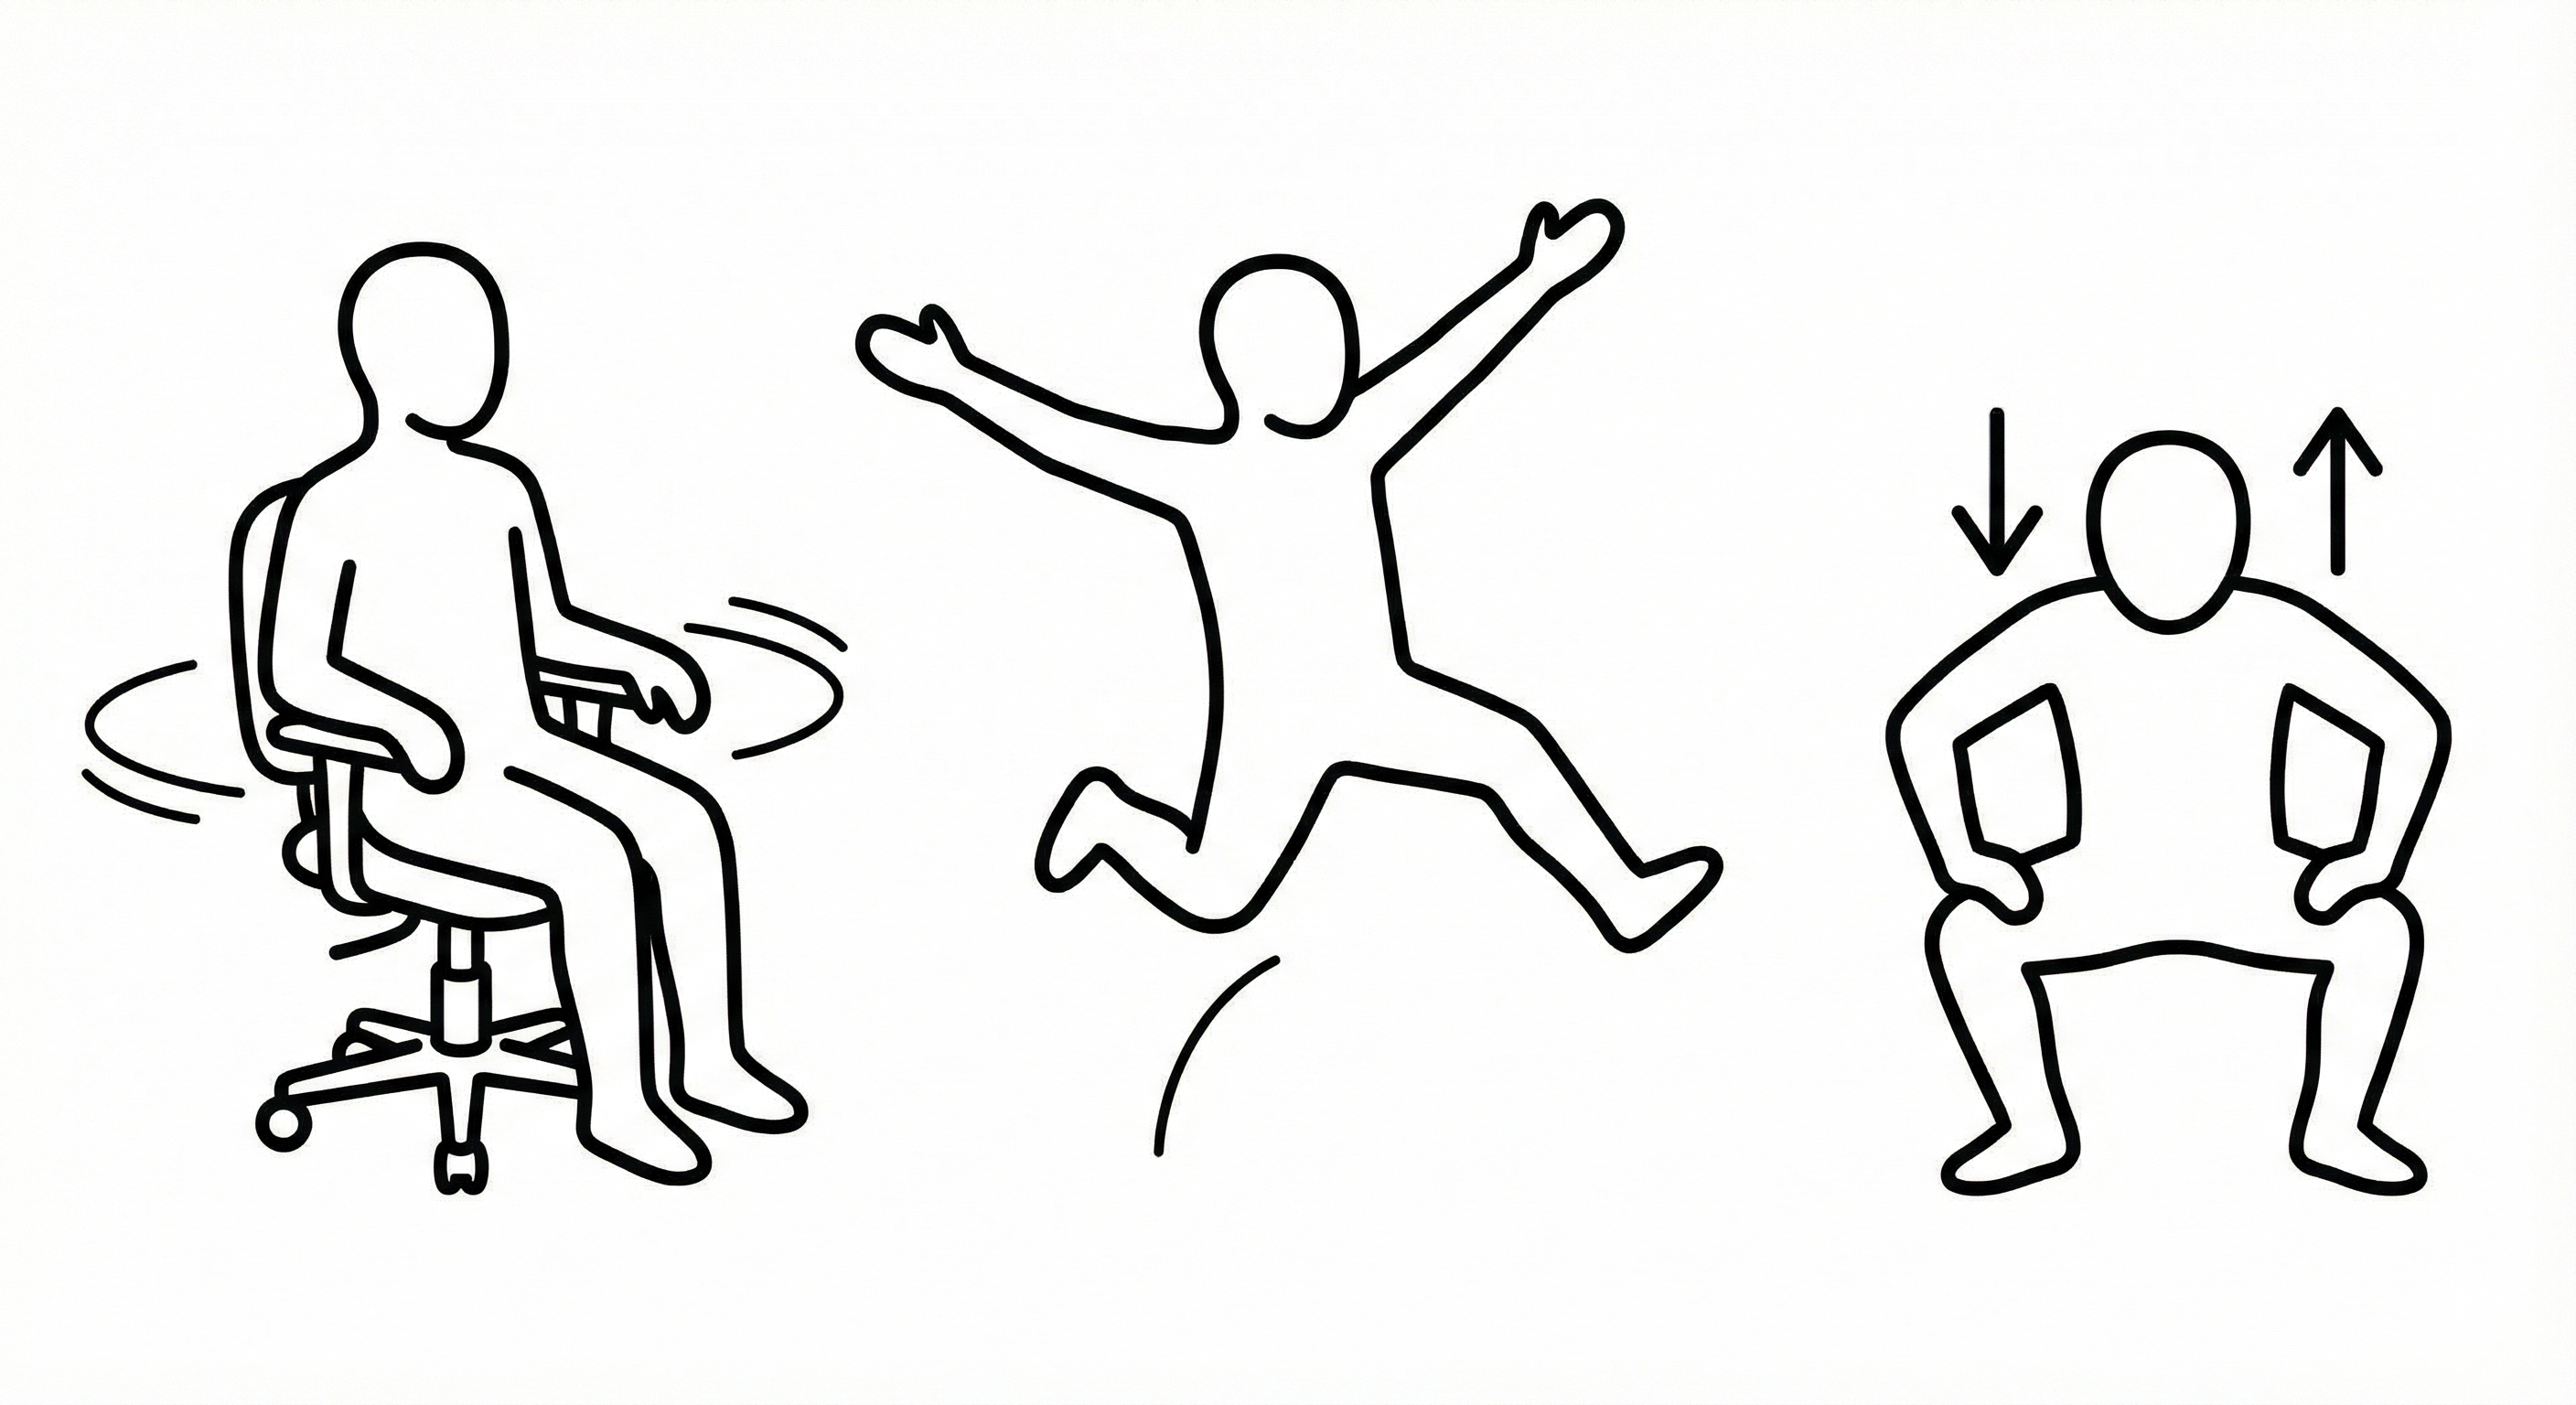

The data was generated with the Phyphox app. We would all place our phones in the same pocket in our pants and realize these actions for a certain amount of time. Afterwards we would export the generated csv file.

One problem we ran into however was that that the beginning and the end of each recording (putting phone in pocket and taking it out at the end) was harmful data because the data on those sections was very different from the rest and could make training more difficult. We had to clean up this data in Excel by looking at the plot and manually cutting the beginning nd end of each recording to have proper data.

Also, we realized that in order to avoid having to record and manually clean hundreds of recordings it was best to record a long set of these actions (I.e. spinning in a chair for 2min) and then make several batches out of it.

In [34]:
#Responsible: Pedro
import os
import re
import math
import pandas as pd
import numpy as np

#This code processes Phyphox CSV files to extract statistical features from accelerometer and gyroscope data.
# It splits large CSV files into smaller chunks and computes mean, standard deviation, min, and max for each axis.

#CSV splitter
def split_csv_into_chunks(input_folder, output_folder=None, chunk_size=50):
    if output_folder is None:
        output_folder = os.path.join(input_folder, 'snippets')
    os.makedirs(output_folder, exist_ok=True)

    for fname in os.listdir(input_folder):
        if not fname.lower().endswith('.csv'):
            continue
        in_path = os.path.join(input_folder, fname)
        try:
            df = pd.read_csv(in_path)
                    
        except Exception as e:
            print(f"Skipping {fname}: read error: {e}")
            continue

        nrows = len(df)
        if nrows == 0:
            print(f"Skipping {fname}: empty file")
            continue

        base = os.path.splitext(fname)[0].replace(' ', '_')
        parts = math.ceil(nrows / chunk_size)
        for i in range(parts):
            start = i * chunk_size
            end = start + chunk_size
            chunk = df.iloc[start:end].copy()
            out_name = f"{base}_part{i+1:03d}.csv"
            out_path = os.path.join(output_folder, out_name)
            chunk.to_csv(out_path, index=False)
        print(f"Wrote {parts} chunks for {fname} -> {output_folder}")

    return output_folder

# 1. CHANGE THIS PATH to the folder containing your Phyphox CSV files
my_folder_path = './HumanActivity'

# Split originals into snippets
snippets_folder = split_csv_into_chunks('./HumanActivity', chunk_size=50)

Wrote 35 chunks for ChairSpin_Haakon.csv -> ./HumanActivity\snippets
Wrote 34 chunks for ChairSpin_Yvette0.csv -> ./HumanActivity\snippets
Wrote 59 chunks for ChairSpin_Yvette1.csv -> ./HumanActivity\snippets
Wrote 16 chunks for Jumping_Haakon.csv -> ./HumanActivity\snippets
Wrote 85 chunks for Jumping_Pedro0.csv -> ./HumanActivity\snippets
Wrote 43 chunks for Jumping_Pedro1.csv -> ./HumanActivity\snippets
Wrote 13 chunks for Jumping_Yvette.csv -> ./HumanActivity\snippets
Wrote 26 chunks for Squats_Haakon.csv -> ./HumanActivity\snippets
Wrote 130 chunks for Squats_Pedro.csv -> ./HumanActivity\snippets
Wrote 44 chunks for Squats_Yvette.csv -> ./HumanActivity\snippets


```
# Place your comments / conclusions / insight here
```


# 3. Explore the data to gain insights.

Explore the data in any possible way, visualize the results (if you have multiple plots of the same kind of data put them in one larger plot)

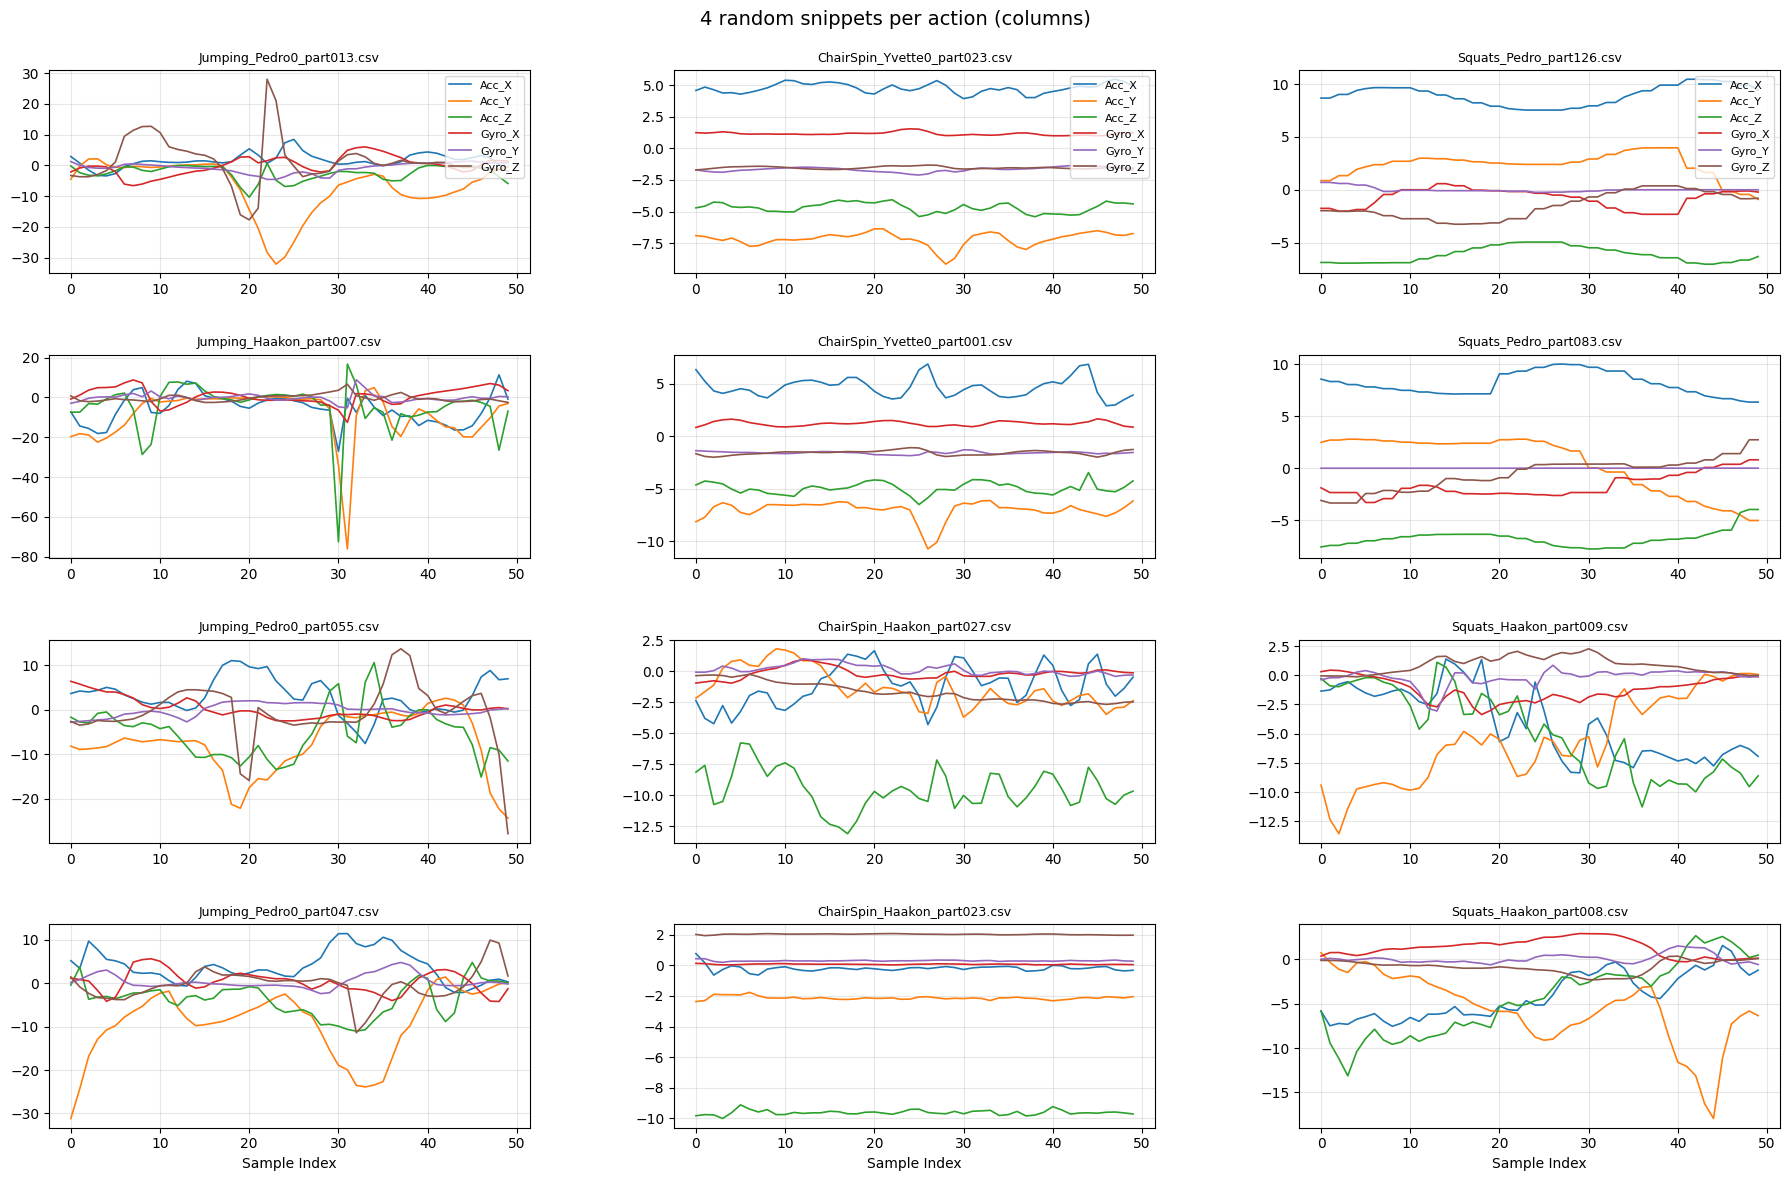

In [ ]:
#Responsible: Pedro
import os
import random
import pandas as pd
import matplotlib.pyplot as plt

# Random seed, useful for reproducibility I guess
#random.seed(42)

snippets_dir = './HumanActivity/snippets'
actions = ['Jumping', 'ChairSpin', 'Squats']   # matching text in filenames (case-insensitive)
per_action = 4

# gather files per action
files_by_action = {}
all_snippets = [f for f in os.listdir(snippets_dir) if f.endswith('.csv')]
for a in actions:
    matches = [f for f in all_snippets if a.lower() in f.lower()]
    files_by_action[a] = matches

# sample files (if fewer than required, take all available)
sampled = {a: random.sample(files_by_action[a], min(per_action, len(files_by_action[a])))
           for a in actions}

# plotting grid: 4 rows x 3 cols (rows = samples)
fig, axes = plt.subplots(per_action, len(actions), figsize=(18, 12), sharex=False)
axis_labels = ['Acc_X','Acc_Y','Acc_Z','Gyro_X','Gyro_Y','Gyro_Z']
colors = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown']

for col_idx, action in enumerate(actions):
    files = sampled[action]
    for row_idx in range(per_action):
        ax = axes[row_idx, col_idx] if per_action > 1 else axes[col_idx]
        if row_idx >= len(files):
            ax.axis('off')
            continue
        fname = files[row_idx]
        fpath = os.path.join(snippets_dir, fname)
        try:
            raw = pd.read_csv(fpath)                # read without explicit sep/decimal
            if raw.shape[1] == 1:
                raw = raw.iloc[:,0].astype(str).str.split(';', expand=True)
            # normalize decimals (comma -> dot) then convert to numeric
            raw = raw.map(lambda x: str(x).replace(',', '.'))
            if raw.shape[1] >= 7:
                data = raw.iloc[:, 1:7].copy()
            else:
                data = raw.iloc[:, :6].copy()
            data = data.apply(pd.to_numeric, errors='coerce')

            if data.shape[1] < 6:
                ax.text(0.5, 0.5, 'Not enough columns', ha='center', va='center')
                ax.set_title(fname)
                ax.axis('off')
                continue

            for i in range(6):
                label = axis_labels[i] if row_idx == 0 else None
                ax.plot(data.iloc[:, i].values, color=colors[i], label=label, linewidth=1.2)
            ax.set_title(fname, fontsize=9)
            if row_idx == 0:
                ax.legend(loc='upper right', fontsize=8)
            ax.grid(alpha=0.3)
            if row_idx == per_action - 1:
                ax.set_xlabel('Sample Index')
        except Exception as e:
            ax.text(0.5, 0.5, f'Error: {e}', ha='center', va='center')
            ax.set_title(fname)

plt.suptitle('4 random snippets per action (columns)', fontsize=14)
plt.tight_layout()
plt.subplots_adjust(top=0.93, hspace=0.4, wspace=0.3)
plt.show()

```
# Place your comments / conclusions / insight here
```
From the plots we can observe that the three actions have very disctinct plots.
- Jumping has values close to zero except very high acceleration spikes periodically.
- Squats have gradually changing accelerations that plot something like a weaving sine waves
- Chair spin doesnt have spikes or sine waves. All measurements stay at 0 or close to zero and maintain that constant value.



# 4. Prepare the data to better expose the underlying data patterns to Machine Learning algorithms

prepare your data, is it normalized? are there outlier? Make a training and a test set.

In [36]:
# Responsible: Pedro

#Feature extractor
def extract_axis_features_from_folder(folder_path):
    features_list = []
    file_names = []
    action_list = []
    name_list = []

    col_labels = ['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z']

    for file in os.listdir(folder_path):
        if file.endswith(".csv"):
            file_path = os.path.join(folder_path, file)
            try:
                df = pd.read_csv(file_path)
                if df.shape[1] >= 7:
                    data = df.iloc[:, 1:7]
                elif df.shape[1] == 6:
                    data = df.iloc[:, :6]
                else:
                    print(f"Skipping {file}: Not enough columns found ({df.shape[1]} columns).")
                    continue

                data = data.apply(pd.to_numeric, errors='coerce')
                if data.empty:
                    print(f"Skipping {file}: Data frame is empty after selection.")
                    continue

                means = data.mean().values
                stds = data.std().values
                mins = data.min().values
                maxs = data.max().values
                feature_vector = np.concatenate([means, stds, mins, maxs])

                features_list.append(feature_vector)
                file_names.append(file)

                # parse Action and Name from filename (handles underscores, spaces or dashes)
                base = os.path.splitext(file)[0]
                parts = re.split('[ _-]+', base)
                action = parts[0] if len(parts) >= 1 else ''
                name = parts[1] if len(parts) >= 2 else ''
                action_list.append(action)
                name_list.append(name)

            except Exception as e:
                print(f"Error processing {file}: {e}")

    stats = ['Mean', 'Std', 'Min', 'Max']
    final_headers = [f"{stat}_{col}" for stat in stats for col in col_labels]

    result_df = pd.DataFrame(features_list, columns=final_headers)
    result_df.insert(0, 'Action', action_list)
    result_df.insert(1, 'Name', name_list)

    return result_df

# 2. Run the functionfeature extractor
features_df = extract_axis_features_from_folder(snippets_folder)

# Print the result (First 5 rows)
print("\nFeatures extracted successfully:")
print(features_df.head())
    
# 3. Optional: Save the features to a new CSV file ready for training
output_file_name = 'extracted_features.csv'
features_df.to_csv(output_file_name, index=False)
print(f"\nFeatures saved to {output_file_name}")


Features extracted successfully:
      Action    Name  Mean_Acc_X  Mean_Acc_Y  Mean_Acc_Z  Mean_Gyro_X  \
0  ChairSpin  Haakon    0.819104   -0.649260   -9.919094     0.066713   
1  ChairSpin  Haakon    0.545447   -1.597316   -9.764476     0.175886   
2  ChairSpin  Haakon   -0.913053   -1.448330   -9.596403    -0.168336   
3  ChairSpin  Haakon   -0.913196   -0.981862   -9.660041     0.137280   
4  ChairSpin  Haakon    0.011875   -1.439107   -9.777884     0.089596   

   Mean_Gyro_Y  Mean_Gyro_Z  Std_Acc_X  Std_Acc_Y  ...  Min_Acc_Z  Min_Gyro_X  \
0     0.108871    -2.280818   0.704283   0.649008  ... -11.209951   -0.318108   
1    -0.028928    -2.436858   0.361688   0.550691  ... -10.520422   -0.178831   
2    -0.274361    -1.319243   1.553387   2.348624  ... -12.960114   -2.181247   
3     0.145756     1.272646   1.102613   0.843848  ... -12.735058   -0.309556   
4     0.173171     1.756781   0.377509   0.317238  ... -10.750265   -0.013286   

   Min_Gyro_Y  Min_Gyro_Z  Max_Acc_X  Ma

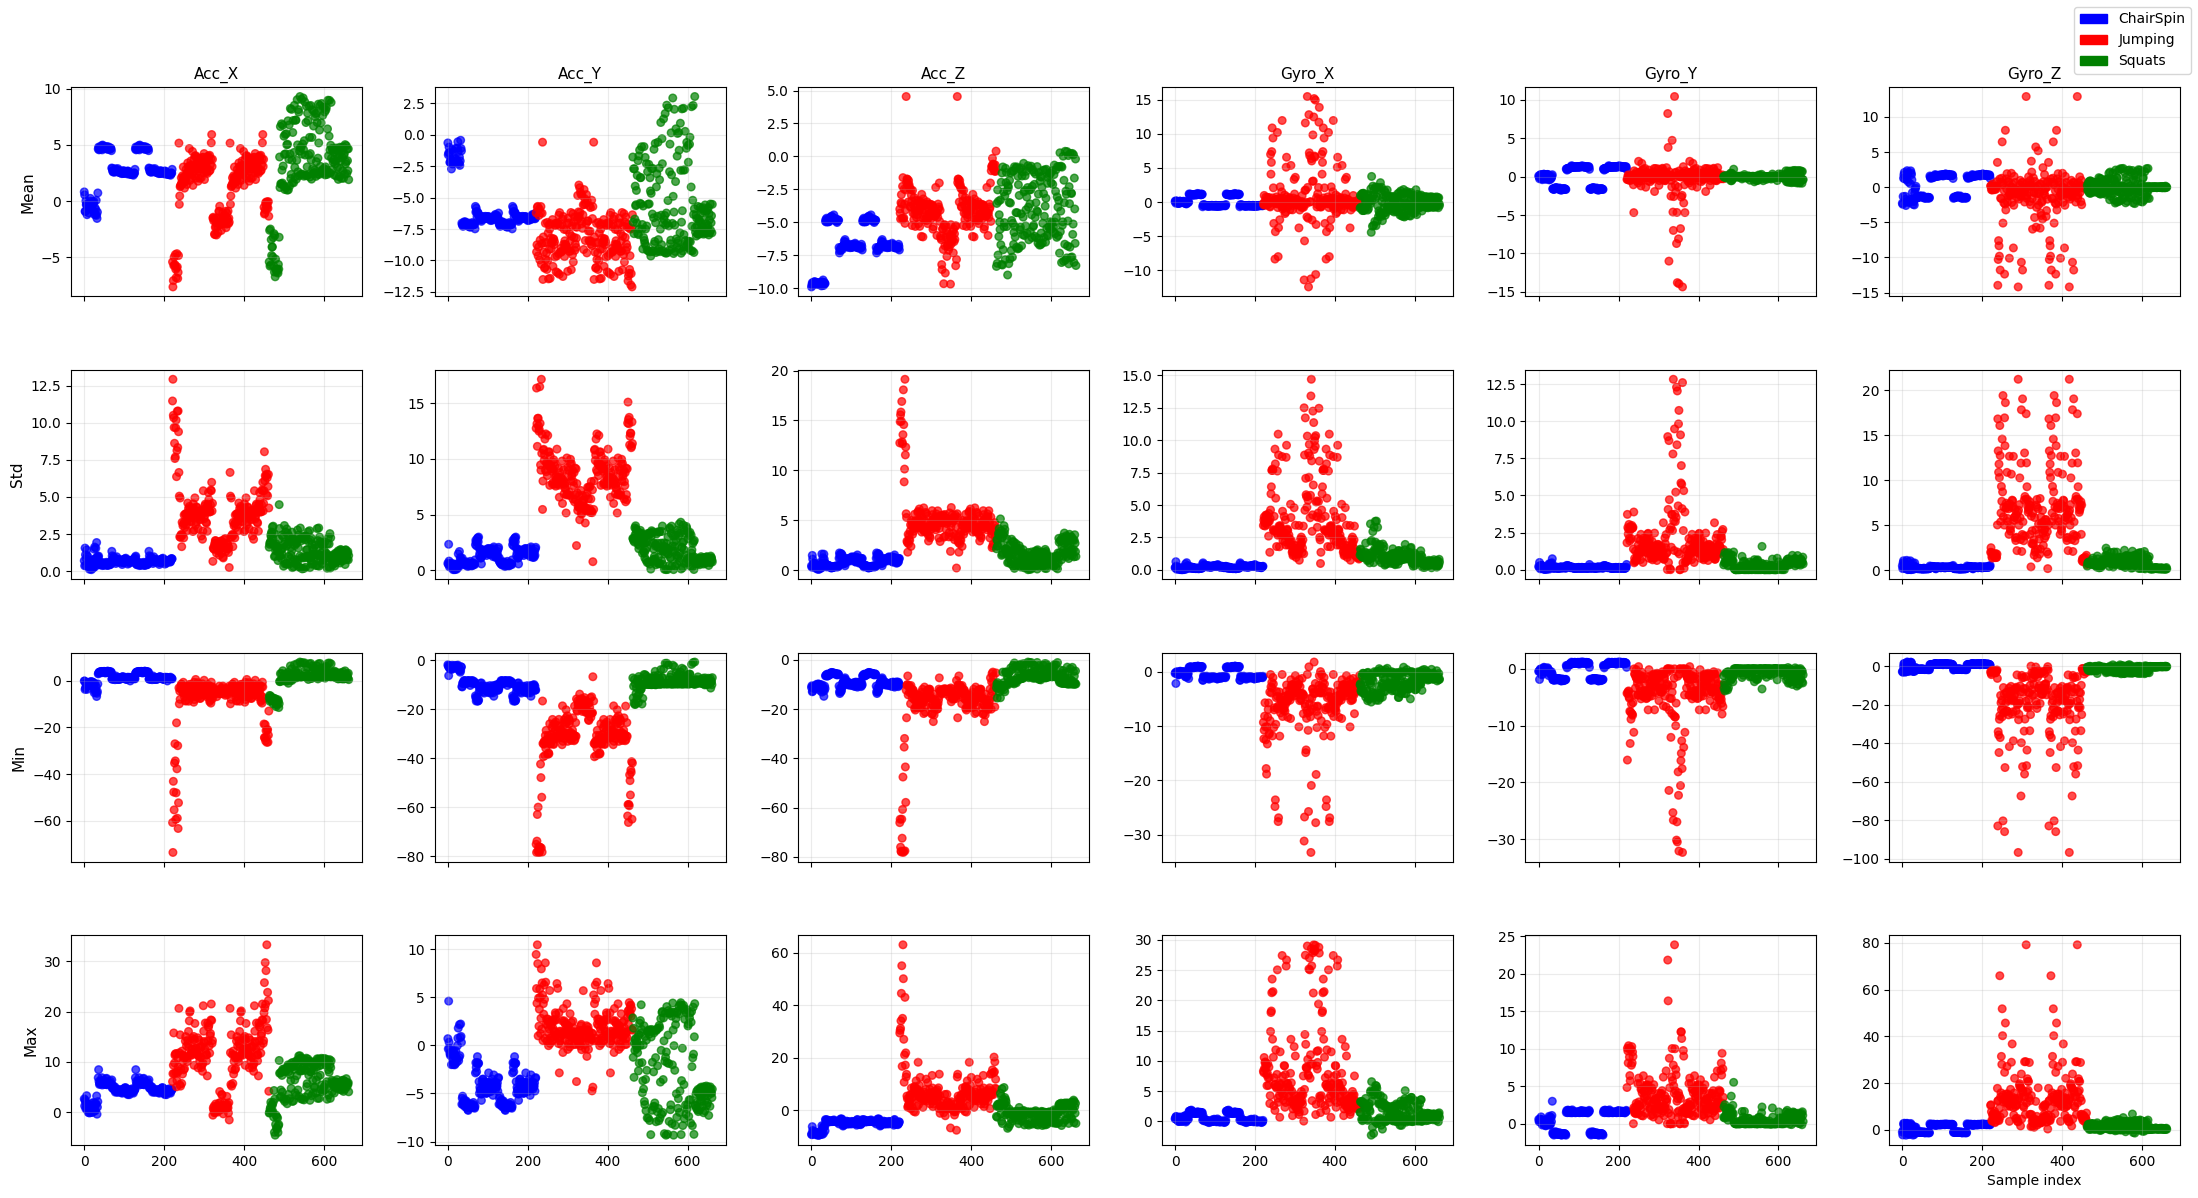

In [20]:
# Responsible: Pedro
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# load
df = pd.read_csv('extracted_features.csv')

# order
stats = ['Mean', 'Std', 'Min', 'Max']
axes_labels = ['Acc_X','Acc_Y','Acc_Z','Gyro_X','Gyro_Y','Gyro_Z']

# colors by action (adjust if you have other action names)
action_colors = {'ChairSpin':'blue', 'Jumping':'red', 'Squats':'green'}
colors = [action_colors.get(a, 'gray') for a in df['Action']]

# make grid 4 rows x 6 cols
rows, cols = len(stats), len(axes_labels)
fig, axs = plt.subplots(rows, cols, figsize=(22, 12), sharex=True)
for r, stat in enumerate(stats):
    for c, ax_label in enumerate(axes_labels):
        colname = f"{stat}_{ax_label}"
        ax = axs[r, c]
        if colname in df.columns:
            ax.scatter(range(len(df)), pd.to_numeric(df[colname], errors='coerce'),
                       c=colors, s=30, alpha=0.7)
        else:
            ax.text(0.5, 0.5, 'N/A', ha='center', va='center')
        if r == 0:
            ax.set_title(ax_label, fontsize=11)
        if c == 0:
            ax.set_ylabel(stat, fontsize=11)
        ax.grid(alpha=0.25)
# common x label
axs[-1, -1].set_xlabel('Sample index')

# legend
legend_handles = [Patch(color=color, label=name) for name, color in action_colors.items()]
fig.legend(handles=legend_handles, loc='upper right', fontsize=10)

plt.tight_layout()
plt.subplots_adjust(top=0.93, hspace=0.35, wspace=0.25)
plt.show()

In [21]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('extracted_features.csv')

if 'Action' in df.columns:
    train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['Action'], random_state=42)
else:
    train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)
test_df  = test_df.sample(frac=1,  random_state=42).reset_index(drop=True)

train_df.to_csv('train_features.csv', index=False)
test_df.to_csv('test_features.csv', index=False)

print(f"Saved train: {len(train_df)} rows -> train_features.csv")
print(f"Saved test : {len(test_df)} rows -> test_features.csv")

Saved train: 530 rows -> train_features.csv
Saved test : 133 rows -> test_features.csv


```
# Place your comments / conclusions / insight here
```
From the features extracted we can 


# 5. Explore many different models and short-list the best ones.

Explore / train and list the top 3 algorithms that score best on this dataset.

In [22]:
#Responsible: Haakon

# Load feature sets
train_df    = pd.read_csv("train_features.csv")
test_df     = pd.read_csv("test_features.csv")

# Show some of the dataset
print(train_df.head())
print(test_df.head())


      Action     Name  Mean_Acc_X  Mean_Acc_Y  Mean_Acc_Z  Mean_Gyro_X  \
0  ChairSpin  Yvette1    2.540675   -6.532848   -6.757953    -0.524415   
1  ChairSpin  Yvette1    2.507056   -6.688466   -6.676801    -0.524513   
2  ChairSpin   Haakon   -0.981096   -1.081940   -9.662818    -0.042058   
3     Squats   Yvette    2.223255   -5.778918   -7.966580    -0.209099   
4     Squats    Pedro    5.775204   -5.213220   -4.652469    -0.493204   

   Mean_Gyro_Y  Mean_Gyro_Z  Std_Acc_X  Std_Acc_Y  ...  Min_Acc_Z  Min_Gyro_X  \
0     1.289111     1.716616   0.611123   1.968790  ... -10.415359   -0.981660   
1     1.306252     1.753845   0.849802   1.353411  ...  -9.089137   -1.040761   
2     0.087992    -0.120738   0.991725   0.684371  ... -10.668862   -0.253967   
3    -0.195303    -0.009291   0.879388   0.830608  ...  -9.538987   -1.064126   
4    -0.212608    -0.823991   1.825402   2.424864  ...  -6.579000   -1.925000   

   Min_Gyro_Y  Min_Gyro_Z  Max_Acc_X  Max_Acc_Y  Max_Acc_Z  Max_Gyro

In [23]:
import tensorflow as tf

# Seperate out features, without labels
features_train = train_df.drop(columns=["Action", "Name"])
features_test = test_df.drop(columns=["Action", "Name"])

# Encoding the label text to label values
label_map = {
    "ChairSpin" : 0,
    "Jumping"   : 1,
    "Squats"    : 2
}

# Seperate out the labels from the dataset
labels_train_int    = train_df["Action"].map(label_map)
labels_test_int     = test_df["Action"].map(label_map)

# Safety check
if labels_train_int.isnull().any() or labels_test_int.isnull().any():
    raise ValueError('Invalid "Action" label detected')

num_classes = len(label_map) # Number of activities we are discerning
labels_train = tf.keras.utils.to_categorical(labels_train_int, num_classes=num_classes)
labels_test  = tf.keras.utils.to_categorical(labels_test_int,  num_classes=num_classes)
# Important: loss must be "categorical_crossentropy"

In [24]:
# Features must be scaled (from 0 to 1)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
features_train = scaler.fit_transform(features_train)
features_test  = scaler.transform(features_test)


In [25]:
# Building model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

model = Sequential([
    Input(shape=(features_train.shape[1],)),    # Arbitrary AI-generated model structure
    Dense(64, activation="relu"),               # Not optimized, but works as a proof-of-concept
    Dense(32, activation="relu"),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,779 (14.76 KB)

 Trainable params: 3,779 (14.76 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# Training the model

NUM_EPOCHS = 100
BATCH_SIZE = 16
VALIDATION_SPLIT = 0.2 
RANDOM_SEED = 42

# Early stopping and callback functionality
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    features_train,
    labels_train,
    epochs=NUM_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7047 - loss: 0.8436 - val_accuracy: 0.9186 - val_loss: 0.5702
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9181 - loss: 0.4642 - val_accuracy: 0.9535 - val_loss: 0.3581
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9503 - loss: 0.2920 - val_accuracy: 0.9767 - val_loss: 0.2309
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9649 - loss: 0.1896 - val_accuracy: 0.9767 - val_loss: 0.1567
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9766 - loss: 0.1321 - val_accuracy: 0.9767 - val_loss: 0.1058
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9766 - loss: 0.0924 - val_accuracy: 0.9767 - val_loss: 0.0760
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9795 - loss: 0.0664 - val_accuracy: 1.0000 - val_loss: 0.0568
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9883 - loss: 0.0510 - val_accuracy: 1.0000 - 

In [27]:
# =========================
# Detailed evaluation
# =========================
from sklearn.metrics import confusion_matrix, classification_report
labels_pred = model.predict(features_test).argmax(axis=1)
labels_true = labels_test.argmax(axis=1)

print("\nConfusion Matrix:")
print(confusion_matrix(labels_true, labels_pred))

print("\nClassification Report:")
print(classification_report(labels_true, labels_pred, target_names=label_map.keys()))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step

Confusion Matrix:
[[44  0  0]
 [ 0 48  1]
 [ 0  0 40]]

Classification Report:
              precision    recall  f1-score   support

   ChairSpin       1.00      1.00      1.00        44
     Jumping       1.00      0.98      0.99        49
      Squats       0.98      1.00      0.99        40

    accuracy                           0.99       133
   macro avg       0.99      0.99      0.99       133
weighted avg       0.99      0.99      0.99       133



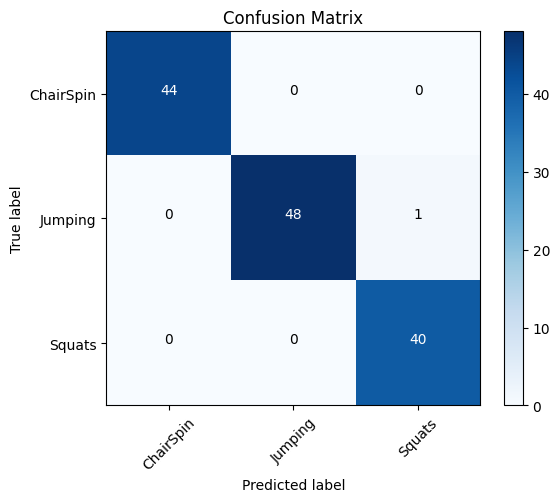

In [28]:
# Make nicer graphic with maptplotlib
import matplotlib.pyplot as plt

cm = confusion_matrix(labels_true, labels_pred)

class_names = list(label_map.keys())

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=45)
plt.yticks(tick_marks, class_names)

# Annotate each cell
thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, cm[i, j],
            horizontalalignment="center",
            color="white" if cm[i, j] > thresh else "black"
        )

plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()


```
# Place your comments / conclusions / insight here
```
From this confusion matrix graph, we can see that the model is correct in 100% of the cases in the test set. Though this might seem great, it is actually very suspicious. Maybe some of the test data has leaked into the training data. Or maybe it is very easy to differentiate the different actions, and therefore not unlikely to get a perfect score.

To see if test data has leaked into the training data, we can check if any of the rows in the two sets are exactly the same 


In [29]:
# Check if there are identical rows
train_rows  = set(map(tuple, train_df.values))
test_rows   = set(map(tuple, test_df.values))

overlap = train_rows.intersection(test_rows)
print("Number of identical rows in training set and test set: ", len(overlap))
if len(overlap) > 0:
    print("Identical rows: ")
    print(overlap)

Number of identical rows in training set and test set:  0


The result above indicates that there are not any direct copies of data from the test set in the training set.


In [30]:
print(train_df["Name"].value_counts())
print()
print(test_df["Name"].value_counts())

Name
Pedro      175
Yvette     114
Pedro0      72
Haakon      62
Yvette1     47
Pedro1      34
Yvette0     26
Name: count, dtype: int64

Name
Pedro      40
Yvette     36
Haakon     15
Pedro0     13
Yvette1    12
Pedro1      9
Yvette0     8
Name: count, dtype: int64


It is possible that it is very easy to seperate the different actions, 
and this is why the previous model is getting a perfect score.
We can test this by purposefully using a very simple model, 
and check how well it performs

In [31]:
# Check if classification can be performed with very simple model
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=1000)
clf.fit(features_train, labels_train.argmax(axis=1))

acc = clf.score(features_test, labels_test.argmax(axis=1))
print("Logistic Regression accuracy:", acc)

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

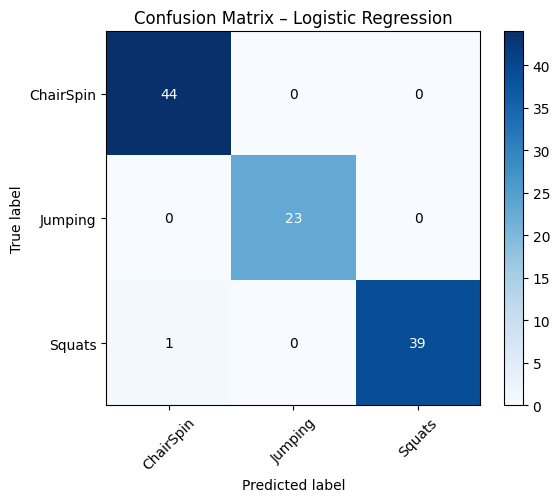

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Predict with Logistic Regression
labels_pred = clf.predict(features_test)
labels_true = labels_test.argmax(axis=1)

# Compute confusion matrix
cm = confusion_matrix(labels_true, labels_pred)

# Class names (ensure consistent order)
class_names = list(label_map.keys())

# Plot confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title("Confusion Matrix – Logistic Regression")
plt.colorbar()

tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=45)
plt.yticks(tick_marks, class_names)

# Annotate each cell with the count
threshold = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()


We see that we get a very high accuracy while using simple model without hidden layers. 
To make this more intuitive, we'll make plot some graphs to show that clusters are clearly seperated.

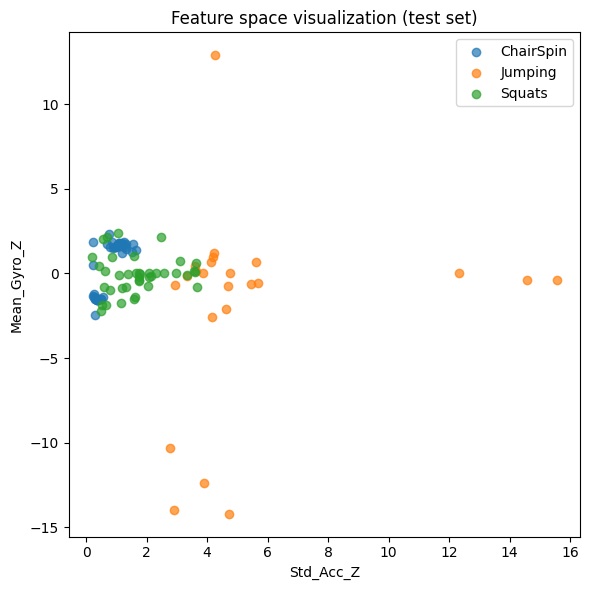

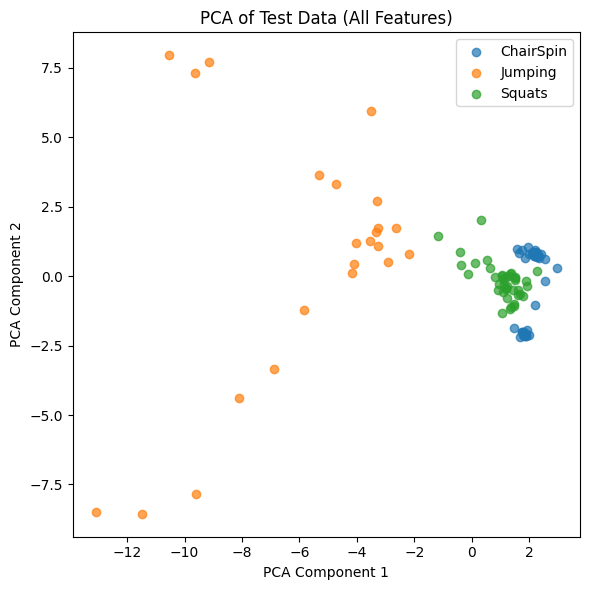

Explained variance: [0.43997326 0.20410518 0.09472202]


In [ ]:
# 2D Scatter plot
import numpy as np

x_feature = "Std_Acc_Z"
y_feature = "Mean_Gyro_Z"

plt.figure(figsize=(6, 6))

for action, idx in label_map.items():
    subset = test_df[test_df["Action"] == action]
    plt.scatter(
        subset[x_feature],
        subset[y_feature],
        label=action,
        alpha=0.7
    )

plt.xlabel(x_feature)
plt.ylabel(y_feature)
plt.title("Feature space visualization (test set)")
plt.legend()
plt.tight_layout()
plt.show()

# PCA projection
from sklearn.decomposition import PCA

# Use scaled features
X_test_scaled = features_test
y_test_labels = labels_test.argmax(axis=1)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_test_scaled)

plt.figure(figsize=(6, 6))

for action, idx in label_map.items():
    plt.scatter(
        X_pca[y_test_labels == idx, 0],
        X_pca[y_test_labels == idx, 1],
        label=action,
        alpha=0.7
    )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("PCA of Test Data (All Features)")
plt.legend()
plt.tight_layout()
plt.show()

pca = PCA(n_components=3)
X_pca_3d = pca.fit_transform(features_test)

print("Explained variance:", pca.explained_variance_ratio_)

From the graphs above, we can intuit that jumping is relatively easy to differantiate, but squats and chairspins are more closely related.

Another way to check for generalization is to use LOSO (Leave one subject out). By removing a subject from the training data, and using them for the test data, it is nigh impossible for test data to leak into the training set. also, during the test there will be a completely new measurement device, subject, test recording etc, making it a good way to test for generalization.

In [41]:
# Read the CSV files (original files remain untouched)
train_df = pd.read_csv("train_features.csv")
test_df = pd.read_csv("test_features.csv")

# Combine into one dataset
full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)

# Show subjects BEFORE renaming
print("Subjects before renaming:")
print(full_df["Name"].value_counts(), "\n")

# A subject is recorded multiple times under different names
# Here we are combining this to one subject
name_mapping = {
    "Yvette0": "Yvette",
    "Yvette1": "Yvette"
}

# Apply renaming (in-memory only)
full_df["Name"] = full_df["Name"].replace(name_mapping)

# Show subjects AFTER renaming
print("Subjects after renaming:")
print(full_df["Name"].value_counts())

# Show per-subject, per-action counts
print("Per-subject action distribution:")
subject_action_counts = (
    full_df
    .groupby(["Name", "Action"])
    .size()
    .unstack(fill_value=0)
)

print(subject_action_counts)

# Final shape check
print("\nCombined dataset shape:", full_df.shape)

Subjects before renaming:
Name
Pedro      215
Yvette     150
Haakon      77
Yvette1     59
Yvette0     34
Name: count, dtype: int64 

Subjects after renaming:
Name
Yvette    243
Pedro     215
Haakon     77
Name: count, dtype: int64
Per-subject action distribution:
Action  ChairSpin  Jumping  Squats
Name                              
Haakon         35       16      26
Pedro           0       85     130
Yvette        186       13      44

Combined dataset shape: (535, 26)


In [14]:
# Seperating into training set and test set
# subject with the least datapoints is used for test set

# Count samples per subject
subject_counts = full_df["Name"].value_counts()

# Identify subject with the least data
test_subject = subject_counts.idxmin()
test_subject_count = subject_counts.min()

print("Samples per subject:")
print(subject_counts, "\n")

print(f"Selected test subject: {test_subject} ({test_subject_count} samples)\n")

# Split the dataset
train_df_subject = full_df[full_df["Name"] != test_subject].reset_index(drop=True)
test_df_subject = full_df[full_df["Name"] == test_subject].reset_index(drop=True)

print("\nTrain subjects:")
print(train_df_subject["Name"].value_counts())

print("\nTest subject:")
print(test_df_subject["Name"].value_counts())

# Separate features and labels
X_train = train_df_subject.drop(columns=["Action", "Name"])
y_train = train_df_subject["Action"]

X_test = test_df_subject.drop(columns=["Action", "Name"])
y_test = test_df_subject["Action"]

# Sanity checks
print("Train set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

print("Random row (training):\n")
print("Features:\n")
print(X_train.sample(n=1), "\n")
print("Label:\n")
print(y_train.sample(n=1), "\n")

print("Random  row (test):\n")
print("Features:\n")
print(X_test.sample(n=1))
print("Label:\n")
print(y_test.sample(n=1))


Samples per subject:
Name
Yvette    243
Pedro     215
Haakon     77
Name: count, dtype: int64 

Selected test subject: Haakon (77 samples)


Train subjects:
Name
Yvette    243
Pedro     215
Name: count, dtype: int64

Test subject:
Name
Haakon    77
Name: count, dtype: int64
Train set shape: (458, 24)
Test set shape: (77, 24)
Random row (training):

Features:

     Mean_Acc_X  Mean_Acc_Y  Mean_Acc_Z  Mean_Gyro_X  Mean_Gyro_Y  \
230    2.517108   -8.735667   -4.644645    -1.140939     0.238824   

     Mean_Gyro_Z  Std_Acc_X  Std_Acc_Y  Std_Acc_Z  Std_Gyro_X  ...  Min_Acc_Z  \
230     0.338649   3.760564   7.865019   4.206657    1.458177  ... -12.387001   

     Min_Gyro_X  Min_Gyro_Y  Min_Gyro_Z  Max_Acc_X  Max_Acc_Y  Max_Acc_Z  \
230   -4.175462   -4.212038  -17.981699  13.003951      2.181    5.98995   

     Max_Gyro_X  Max_Gyro_Y  Max_Gyro_Z  
230      0.9119    3.226438   19.726713  

[1 rows x 24 columns] 

Label:

319    ChairSpin
Name: Action, dtype: object 

Random  row (test):

In [34]:
# Seperate out the labels from the dataset
labels_train_int    = train_df_subject["Action"].map(label_map)
labels_test_int     = test_df_subject["Action"].map(label_map)

# Safety check
if labels_train_int.isnull().any() or labels_test_int.isnull().any():
    raise ValueError('Invalid "Action" label detected')

num_classes = len(label_map) # Number of activities we are discerning
labels_train = tf.keras.utils.to_categorical(labels_train_int, num_classes=num_classes)
labels_test  = tf.keras.utils.to_categorical(labels_test_int,  num_classes=num_classes)

In [35]:
# Scaling features

scaler = StandardScaler()
features_train = scaler.fit_transform(X_train)
features_test  = scaler.transform(X_test)

In [36]:
# Defining basic model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

model = Sequential([
    Input(shape=(features_train.shape[1],)),    # Arbitrary AI-generated model structure
    Dense(64, activation="relu"),               # Not optimized, but works as a proof-of-concept
    Dense(32, activation="relu"),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,779 (14.76 KB)

 Trainable params: 3,779 (14.76 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
# Training the model

NUM_EPOCHS = 200
BATCH_SIZE = 16
VALIDATION_SPLIT = 0.2 
RANDOM_SEED = 42

# Early stopping and callback functionality
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    features_train,
    labels_train,
    epochs=NUM_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 7.7844e-07 - val_accuracy: 1.0000 - val_loss: 7.6967e-07
Epoch 2/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 7.6736e-07 - val_accuracy: 1.0000 - val_loss: 7.6320e-07
Epoch 3/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 7.5759e-07 - val_accuracy: 1.0000 - val_loss: 7.5801e-07
Epoch 4/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 7.4619e-07 - val_accuracy: 1.0000 - val_loss: 7.5153e-07
Epoch 5/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 7.3349e-07 - val_accuracy: 1.0000 - val_loss: 7.4506e-07
Epoch 6/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 7.2274e-07 - val_accuracy: 1.0000 - val_loss: 7.3728e-07
Epoch 7/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 7.1167e-07 - val_accuracy: 1.0000 - val_loss: 7.2951e-07
Epoch 8/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - ac

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 

Confusion Matrix:
[[ 0  0 35]
 [ 0 16  0]
 [ 0  3 23]]

Classification Report:
              precision    recall  f1-score   support

   ChairSpin       0.00      0.00      0.00        35
     Jumping       0.84      1.00      0.91        16
      Squats       0.40      0.88      0.55        26

    accuracy                           0.51        77
   macro avg       0.41      0.63      0.49        77
weighted avg       0.31      0.51      0.37        77



C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Test\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classif

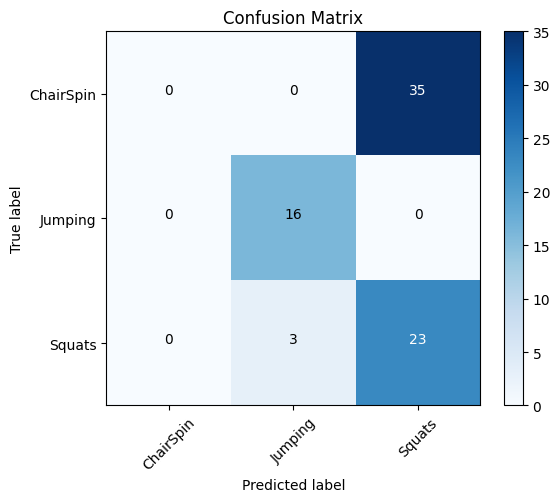

In [48]:
# =========================
# Detailed evaluation
# =========================
from sklearn.metrics import confusion_matrix, classification_report
labels_pred = model.predict(features_test).argmax(axis=1)
labels_true = labels_test.argmax(axis=1)

print("\nConfusion Matrix:")
print(confusion_matrix(labels_true, labels_pred))

print("\nClassification Report:")
print(classification_report(labels_true, labels_pred, target_names=label_map.keys()))

# Make nicer graphic with maptplotlib
import matplotlib.pyplot as plt

cm = confusion_matrix(labels_true, labels_pred)

class_names = list(label_map.keys())

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=45)
plt.yticks(tick_marks, class_names)

# Annotate each cell
thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, cm[i, j],
            horizontalalignment="center",
            color="white" if cm[i, j] > thresh else "black"
        )

plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()


# 6. Fine-tune your models and combine them into a great solution.

can you get better performance within a model? e.g if you use a KNN classifier how does it behave if you change K (k=3 vs k=5 vs k=?). Which parameters are here to tune in the chosen models? 

From what is discussed in chapter 5, it seems to be that the actions are so clearly distinct from eachother that there are only small marginal gains to be made from using deep learning. 

In [ ]:
#Responsible: Haakon
# YOUR CODE HERE 



```
# Place your comments / conclusions / insight here
```


# 7. Present your solution.

Explain why you would choose for a specific model

In [ ]:
#Responsible: Haakon
# YOUR CODE HERE 

```
# Place your comments / conclusions / insight here
```


# 8. Launch, monitor, and maintain your system.

Responsible: Yvette

Can you Deployment the model?

> NOTE: The app provides the option for remote access, so you are able to get live sensordata from the phone

In [ ]:
# This section deals with the deployment of the model

# ==========================================
# Section 8: Live Deployment & Monitoring
# ==========================================

import requests
import time
import numpy as np
import pandas as pd

# 1. SETUP: Replace with the IP displayed in your Phyphox app
# Ensure the URL includes all 6 sensor parameters
PHYPHOX_URL = "http://192.168.1.49:8080/get?accX&accY&accZ&gyroX&gyroY&gyroZ" # Should make sure the IP matches the phone running the experiment.
class_names = ["ChairSpin", "Jumping", "Squats"]


try:
    while True:
        live_buffer = []
        print("\n--- Starting Collection Window ---")
        
        # 2. COLLECTION: Fill buffer until we have 50 valid samples
        start_time = time.time()
        timeout_duration = 5.0  # Max time to wait for a full window (prevent infinite loops)
        
        while len(live_buffer) < 50:
            # Safety break: If we can't fill the buffer in 5 seconds, drop it and restart
            if (time.time() - start_time) > timeout_duration:
                print("Window timeout - restarting collection")
                break

            try:
                # Get JSON data
                response = requests.get(PHYPHOX_URL, timeout=0.5).json()
                buffer_data = response.get('buffer', {})
                
                sample = [
                    buffer_data.get('accX', {}).get('buffer', [0.0])[0],
                    buffer_data.get('accY', {}).get('buffer', [0.0])[0],
                    buffer_data.get('accZ', {}).get('buffer', [0.0])[0],
                    buffer_data.get('gyroX', {}).get('buffer', [0.0])[0],
                    buffer_data.get('gyroY', {}).get('buffer', [0.0])[0],
                    buffer_data.get('gyroZ', {}).get('buffer', [0.0])[0]
                ]
                live_buffer.append(sample)
                
                # OPTIONAL: Remove the sleep. 
                # The network request itself takes time (>20ms), so you are likely 
                # naturally limited to <50Hz anyway.
                # time.sleep(0.02) 

            except Exception:
                # If a request fails, we just loop again immediately 
                # without incrementing the buffer count.
                continue

        # 3. FEATURE EXTRACTION: Convert 50 samples into the 24-feature vector
        # Labels must match the order used in extract_axis_features_from_folder
        cols = ['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z']
        df_live = pd.DataFrame(live_buffer, columns=cols)
        
        # Calculate stats in the exact order: Means, Stds, Mins, Maxs
        # This order is critical for the StandardScaler to work correctly
        means = df_live.mean().values
        stds = df_live.std().values
        mins = df_live.min().values
        maxs = df_live.max().values
        
        # Combine into a single row for the model
        feature_vector = np.concatenate([means, stds, mins, maxs]).reshape(1, -1)

        # 4. PREDICTION: Standardize and Classify
        # We use the 'scaler' instance fit during the training block
        scaled_features = scaler.transform(feature_vector) 
        prediction_probs = model.predict(scaled_features, verbose=0)
        
        predicted_idx = np.argmax(prediction_probs)
        predicted_class = class_names[predicted_idx]
        confidence = prediction_probs[0][predicted_idx] * 100

        # 5. MONITOR: Output live results
        print(f"Prediction: {predicted_class}")
        print(f"Confidence: {confidence:.2f}%")
        # Print all probabilities to see how the model is weighing alternatives
        print(f"Raw Probabilities: {np.round(prediction_probs, 3)}")

except KeyboardInterrupt:
    print("\nSystem Shutdown.")
except Exception as global_error:
    print(f"Critical System Error: {global_error}")

System Launching... Press Ctrl+C to stop.

--- Starting Collection Window ---

--- Starting Collection Window ---

--- Starting Collection Window ---

--- Starting Collection Window ---

--- Starting Collection Window ---


c:\Users\Pedro\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Prediction: Squats
Confidence: 100.00%
Raw Probabilities: [[0. 0. 1.]]

--- Starting Collection Window ---

--- Starting Collection Window ---

--- Starting Collection Window ---

--- Starting Collection Window ---

--- Starting Collection Window ---

--- Starting Collection Window ---

--- Starting Collection Window ---

--- Starting Collection Window ---

--- Starting Collection Window ---

--- Starting Collection Window ---

--- Starting Collection Window ---

--- Starting Collection Window ---

System Shutdown.


# 9. Additional Questions

Responsible: Yvette

* Explain the chosen motions you chose to be classified. 

The motions we chose were spinning in a chair, jumping in place, and squatting. We chose these because we thought they would be distinct enough for the model to be able to classify them as different from one another. Each motion was also easy enough to perform such that it wouldn’t be difficult to gather more data if needed. Lastly, each motion was different from those listed in the assignment description.

* Which of these motions is easier/harder to classify and why?

At first, when the model had the dataset to work with, it was easy for it to classify each motion. However, after the live deployment we found that when we would bend our knees to perform a jump or stand idly it would register these as a squat.

* After your experience, which extra sensor data might help getting a better classifier and why?

Due to the issue mentioned above it would be helpful to add a barometric sensor. It is easier for an accelerometer to mistake squats and jumps, however, if there was an additional barometric sensor it would make it possible for the small difference in air pressure to also be detected during the phase (during a jump) where each person is completely in the air (highest point).

* Explain why you think that your chosen algorithm outperforms the rest? 

* While recording the same motions with the same sensor data, what do you think will help improving the performance of your models?


```
# Place your comments / conclusions / insight here
```
